# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


## 0. Setup

In [2]:
!pip install -q mlflow optuna


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.2/44.2 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 104.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 76.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [4]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [5]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [7]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)

In [8]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


### Explicación del TODO 1: `preprocess_text`

| Componente | Qué hace |
|---|---|
| `word_tokenize` | Separa el texto en tokens (palabras y signos de puntuación) usando el modelo `punkt`. |
| `stopwords.words("english")` | Lista de ~180–200 palabras muy frecuentes y poco informativas (*the, is, and, of...*). |
| `PorterStemmer` | Recorta sufijos con reglas fijas (*running → run*, *studies → studi*). |
| `WordNetLemmatizer` | Busca la forma de diccionario de la palabra en WordNet (*engines → engine*). |

**Qué hace el código:**
1. Pasa el texto a minúsculas y lo tokeniza.
2. Con `isalpha()` descarta números y puntuación.
3. Si `remove_stopwords=True`, filtra las stopwords con una list comprehension.
4. Aplica `STEMMER.stem` o `LEMMATIZER.lemmatize` a cada token, según `normalization`.
5. Une los tokens con espacios, porque `TfidfVectorizer` espera recibir strings.

## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [9]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # TODO: crear un TfidfVectorizer con los parámetros recibidos y ajustarlo (fit) sobre train_texts,
    # después transformar train_texts y test_texts con ese mismo vectorizer.
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [10]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


### Explicación del TODO 2: `vectorize_data`
**Framework: scikit-learn.** Librería de machine learning clásico. `TfidfVectorizer` convierte cada texto en un vector con una posición por término del vocabulario y un peso TF-IDF en cada posición:

- **TF**: cantidad de veces que el término aparece en el documento.
- **IDF**: `idf(t) = ln((1+n)/(1+df(t))) + 1`, donde `n` es la cantidad de documentos y `df(t)` la cantidad de documentos que contienen `t`. Los términos raros reciben más peso.
- Peso final: `tf · idf`. Después, cada vector se normaliza con norma L2 igual a 1.
- `fit_transform(train_texts)` aprende el vocabulario (respetando `ngram_range`, `max_features` y `min_df`) y los valores de IDF, y además transforma el train.
- `transform(test_texts)` usa ese mismo vocabulario e IDF para transformar el test.

## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [11]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # TODO: definir una única capa lineal de input_dim a num_classes
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # TODO: devolver los logits (salida de self.linear), SIN aplicar softmax
        return self.linear(x)

In [12]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


### Explicación del TODO 3: `SoftmaxRegression`

**Framework: PyTorch.** Librería de deep learning. Un modelo se define como una subclase de `nn.Module`:
- En `__init__` se declaran las capas, cuyos parámetros PyTorch registra automáticamente.
- En `forward` se define el cálculo del modelo.
- PyTorch arma el grafo de operaciones y calcula los gradientes con `loss.backward()` (autograd).

- `nn.Linear(input_dim, num_classes)` contiene una matriz de pesos `W` (num_classes × input_dim) y un vector de sesgos `b` (num_classes). Calcula `z = Wx + b`, es decir, un **logit** por clase. Cada fila de `W` funciona como un "detector" de una clase: una suma ponderada de las features TF-IDF.
- `forward` devuelve los logits **sin softmax**, porque `nn.CrossEntropyLoss` ya aplica `log_softmax` internamente, de forma numéricamente estable. Para predecir alcanza con `argmax(z)`, ya que la softmax no cambia cuál es el máximo.
- No hay capas ocultas ni activaciones: es un modelo lineal.

**Cantidad de parámetros:**
- En el sanity check: 50·20 + 20 = 1.020.
- En el modelo final (10.000 features): 10.000·20 + 20 = 200.020.

## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [13]:
%load_ext tensorboard


In [14]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

    return history


## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [15]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [16]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}")

    return history["val_acc"][-1]


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)


[I 2026-09-28 18:34:35,630] A new study created in memory with name: no-name-9caa425a-3b49-4023-b21a-be1cf73213aa


[trial_0] Epoch 1/5 - train_loss: 2.8690 train_acc: 0.4991 - val_loss: 2.7407 val_acc: 0.6235


2026/09/28 18:34:49 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/28 18:34:50 INFO mlflow.store.db.utils: Updating database tables


[trial_0] Epoch 2/5 - train_loss: 2.5814 train_acc: 0.7477 - val_loss: 2.5242 val_acc: 0.6394
[trial_0] Epoch 3/5 - train_loss: 2.3333 train_acc: 0.7910 - val_loss: 2.3360 val_acc: 0.6522
[trial_0] Epoch 4/5 - train_loss: 2.1157 train_acc: 0.8110 - val_loss: 2.1744 val_acc: 0.6637


[I 2026-09-28 18:34:55,037] Trial 0 finished with value: 0.6760936809544852 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.0011616283411564812, 'batch_size': 32}. Best is trial 0 with value: 0.6760936809544852.


...

[trial_12] Epoch 5/5 - train_loss: 0.1753 train_acc: 0.9677 - val_loss: 1.0537 val_acc: 0.6951
[trial_13] Epoch 1/5 - train_loss: 1.8891 train_acc: 0.6151 - val_loss: 1.2901 val_acc: 0.7194
[trial_13] Epoch 2/5 - train_loss: 0.7739 train_acc: 0.8756 - val_loss: 1.0644 val_acc: 0.7340
[trial_13] Epoch 3/5 - train_loss: 0.4847 train_acc: 0.9272 - val_loss: 0.9928 val_acc: 0.7335
[trial_13] Epoch 4/5 - train_loss: 0.3461 train_acc: 0.9490 - val_loss: 0.9612 val_acc: 0.7362


[I 2026-09-28 18:35:59,432] Trial 13 finished with value: 0.7313300927971719 and parameters: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.017236837158407122, 'batch_size': 32}. Best is trial 13 with value: 0.7313300927971719.


[trial_13] Epoch 5/5 - train_loss: 0.2674 train_acc: 0.9587 - val_loss: 0.9489 val_acc: 0.7313
[trial_14] Epoch 1/5 - train_loss: 2.2019 train_acc: 0.5733 - val_loss: 1.6102 val_acc: 0.7079
[trial_14] Epoch 2/5 - train_loss: 1.0271 train_acc: 0.8781 - val_loss: 1.2590 val_acc: 0.7163
[trial_14] Epoch 3/5 - train_loss: 0.6556 train_acc: 0.9212 - val_loss: 1.1319 val_acc: 0.7181
[trial_14] Epoch 4/5 - train_loss: 0.4766 train_acc: 0.9424 - val_loss: 1.0702 val_acc: 0.7198


[I 2026-09-28 18:36:03,176] Trial 14 finished with value: 0.7176314626601856 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.02292344389036036, 'batch_size': 128}. Best is trial 13 with value: 0.7313300927971719.


[trial_14] Epoch 5/5 - train_loss: 0.3724 train_acc: 0.9539 - val_loss: 1.0402 val_acc: 0.7176
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.017236837158407122, 'batch_size': 32}
Mejor accuracy de validación: 0.7313300927971719


### Análisis de la búsqueda de hiperparámetros

**Framework: Optuna.** Librería de optimización de hiperparámetros:
- `create_study(direction="maximize")` crea un estudio que busca maximizar el valor que devuelve `objective`.
- En cada *trial*, `suggest_categorical` y `suggest_float(..., log=True)` proponen valores. El `lr` se muestrea en escala logarítmica, así que se exploran de forma pareja los órdenes de magnitud entre 0.001 y 0.1.
- El sampler por defecto es **TPE** (bayesiano): usa los resultados de los trials anteriores para proponer valores en las zonas más prometedoras.

El objetivo es el `val_acc` de la **última época (5)**, medido sobre un 20 % del train separado como validación. El test no se usa en esta etapa.

**Resultados de los 15 trials:**

| Trial | Stopwords | Norm. | N-gramas | max_feat | min_df | lr | batch | val_acc | Duración (s) |
|---|---|---|---|---|---|---|---|---|---|
| 0 | sí | lemma | 1-2 | 5000 | 2 | 0.0012 | 32 | 0.676 | 19.4* |
| 1 | no | lemma | 1 | 5000 | 5 | 0.0040 | 32 | 0.700 | 4.1 |
| 2 | no | stem | 1-2 | 10000 | 1 | 0.0010 | 128 | 0.609 | 8.5 |
| 3 | sí | none | 1-2 | 2000 | 1 | 0.0040 | 32 | 0.626 | 6.2 |
| 4 | no | lemma | 1-2 | 5000 | 5 | 0.0415 | 64 | 0.627 | 6.8 |
| 5 | sí | stem | 1 | 2000 | 1 | 0.0060 | 64 | 0.654 | 2.0 |
| 6 | sí | none | 1-2 | 5000 | 2 | 0.0839 | 32 | 0.647 | 7.0 |
| 7 | no | lemma | 1 | 2000 | 2 | 0.0151 | 64 | 0.635 | 2.5 |
| 8 | no | none | 1-2 | 10000 | 2 | 0.0442 | 64 | 0.640 | 8.7 |
| 9 | sí | stem | 1 | 10000 | 2 | 0.0428 | 64 | 0.724 | 3.8 |
| 10 | sí | stem | 1 | 10000 | 2 | 0.0015 | 64 | 0.705 | 4.1 |
| 11 | sí | stem | 1 | 10000 | 2 | 0.0592 | 64 | 0.721 | 3.5 |
| 12 | sí | stem | 1 | 5000 | 2 | 0.0540 | 64 | 0.695 | 2.6 |
| **13** | **sí** | **stem** | **1** | **10000** | **2** | **0.0172** | **32** | **0.731** | 4.6 |
| 14 | sí | none | 1 | 10000 | 2 | 0.0229 | 128 | 0.718 | 3.8 |


**Mejor configuración (trial 13):** stopwords, stemming, unigramas, 10.000 features, `min_df=2`, `lr≈0.017`, `batch_size=32`, con **val_acc = 0.731**.

**Promedio de val_acc según cada hiperparámetro:**

| Hiperparámetro | Valor → val_acc media (cantidad de trials) |
|---|---|
| N-gramas | unigramas 0.698 (9) · uni+bigramas 0.637 (6) |
| max_features | 2000: 0.638 (3) · 5000: 0.669 (5) · 10000: 0.692 (7) |
| Stopwords | sacarlas 0.690 (10) · dejarlas 0.642 (5) |
| Normalización | stem 0.691 (7) · lemma 0.659 (4) · none 0.658 (4) |



## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

In [20]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 20

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target),
                                 batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
                                batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)
writer = SummaryWriter(log_dir="runs/softmax_final")

mlflow.set_experiment("softmax_20newsgroups")

# Ensure no active run before starting a new one
if mlflow.active_run():
    mlflow.end_run()

with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({
        "remove_stopwords": BEST_REMOVE_SW, "normalization": BEST_NORM,
        "ngram_range": str(BEST_NGRAM), "max_features": BEST_MAX_FEATURES, "min_df": BEST_MIN_DF,
        "lr": BEST_LR, "batch_size": BEST_BATCH_SIZE, "epochs": EPOCHS_FINAL,
    })
    history = train_softmax_model(model, train_loader_final, test_loader_final, optimizer,
                                   epochs=EPOCHS_FINAL, writer=writer, run_name="final")
    # Removed input_example as it was causing conflicts with serialization_format='pickle'
    mlflow.pytorch.log_model(model, "model", serialization_format='pickle')

writer.close()

[final] Epoch 1/20 - train_loss: 1.7603 train_acc: 0.6418 - val_loss: 1.3572 val_acc: 0.6715
[final] Epoch 2/20 - train_loss: 0.7110 train_acc: 0.8763 - val_loss: 1.1989 val_acc: 0.6772
[final] Epoch 3/20 - train_loss: 0.4540 train_acc: 0.9227 - val_loss: 1.1626 val_acc: 0.6702
[final] Epoch 4/20 - train_loss: 0.3282 train_acc: 0.9463 - val_loss: 1.1550 val_acc: 0.6690
[final] Epoch 5/20 - train_loss: 0.2558 train_acc: 0.9581 - val_loss: 1.1609 val_acc: 0.6657
[final] Epoch 6/20 - train_loss: 0.2103 train_acc: 0.9647 - val_loss: 1.1738 val_acc: 0.6640
[final] Epoch 7/20 - train_loss: 0.1801 train_acc: 0.9677 - val_loss: 1.1907 val_acc: 0.6622
[final] Epoch 8/20 - train_loss: 0.1595 train_acc: 0.9686 - val_loss: 1.2064 val_acc: 0.6584
[final] Epoch 9/20 - train_loss: 0.1441 train_acc: 0.9705 - val_loss: 1.2260 val_acc: 0.6563
[final] Epoch 10/20 - train_loss: 0.1326 train_acc: 0.9707 - val_loss: 1.2462 val_acc: 0.6549
[final] Epoch 11/20 - train_loss: 0.1242 train_acc: 0.9711 - val_loss

2026/09/28 18:40:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/28 18:40:12 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


[final] Epoch 20/20 - train_loss: 0.0954 train_acc: 0.9719 - val_loss: 1.4602 val_acc: 0.6415


2026/09/28 18:40:12 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/09/28 18:40:20 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


In [ ]:
%tensorboard --logdir runs


### Dinámica y convergencia de los entrenamientos

Para seguir los entrenamientos usamos dos herramientas:
- **TensorBoard**, para ver las curvas de loss y accuracy por época.
- **MLflow**, para guardar los hiperparámetros, las métricas y el modelo de cada corrida.

**Dinámica según el learning rate**

Mirando los trials de Optuna, el learning rate es lo que más cambia la forma en que entrena el modelo:

| lr | Ejemplo | Qué pasa |
|---|---|---|
| Bajo (~0.001) | Trial 10 | La loss baja muy despacio (de 2.89 a 2.01 en 5 épocas) y el val_acc sigue subiendo al final. No llega a converger. |
| Medio (~0.02) | Trial 13 | La loss baja bien y el val_acc se estabiliza alrededor de la época 4. |
| Alto (~0.05) | Trial 11 | El mejor val_acc aparece en la época 1. Después la val_loss empieza a subir: el modelo sobreajusta. |

En todos los casos, la loss arranca cerca de 3, que es ln(20): el valor que da un modelo que asigna la misma probabilidad a las 20 clases.

**Entrenamiento final**

Con 20 épocas se ve claramente el overfitting:
- La train_loss baja hasta 0.095 y el train_acc llega a 0.97.
- El mejor val_acc (0.677) es de la época 2, y el mínimo de val_loss es de la época 4.
- Desde ahí, la val_loss sube hasta 1.46 y el val_acc baja a 0.64.

Para este lr, 20 épocas son demasiadas. Early stopping o regularización (weight_decay) habrían ayudado. Hay que tener en cuenta que acá la validación es el test, así que no se debería elegir la época mirando estas curvas.

**Tiempos de convergencia**

- **En épocas:** con lr alto el modelo converge en 1–2 épocas, con lr medio en 4–5, y con lr bajo no llega a converger en 5.
- **En segundos:** la búsqueda completa tardó alrededor de 1.5 minutos. Los trials con bigramas tardaron entre 6 y 9 s, contra 2–4 s de los de unigramas, porque vectorizar con bigramas es mucho más pesado. Un batch_size más chico también suma un poco de tiempo, porque hay más pasos por época.
- Lo más lento de todo fue el preprocesamiento con NLTK. Por eso se calcula una sola vez y se guarda en caché.

## 8. Evaluación final

In [21]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Accuracy en test: 0.6415

                          precision    recall  f1-score   support

             alt.atheism       0.49      0.46      0.48       319
           comp.graphics       0.57      0.61      0.59       389
 comp.os.ms-windows.misc       0.55      0.58      0.56       394
comp.sys.ibm.pc.hardware       0.55      0.57      0.56       392
   comp.sys.mac.hardware       0.62      0.62      0.62       385
          comp.windows.x       0.75      0.59      0.66       395
            misc.forsale       0.74      0.75      0.74       390
               rec.autos       0.45      0.72      0.55       396
         rec.motorcycles       0.75      0.68      0.71       398
      rec.sport.baseball       0.82      0.76      0.79       397
        rec.sport.hockey       0.89      0.83      0.86       399
               sci.crypt       0.77      0.71      0.73       396
         sci.electronics       0.57      0.55      0.56       393
                 sci.med       0.74      0.73    

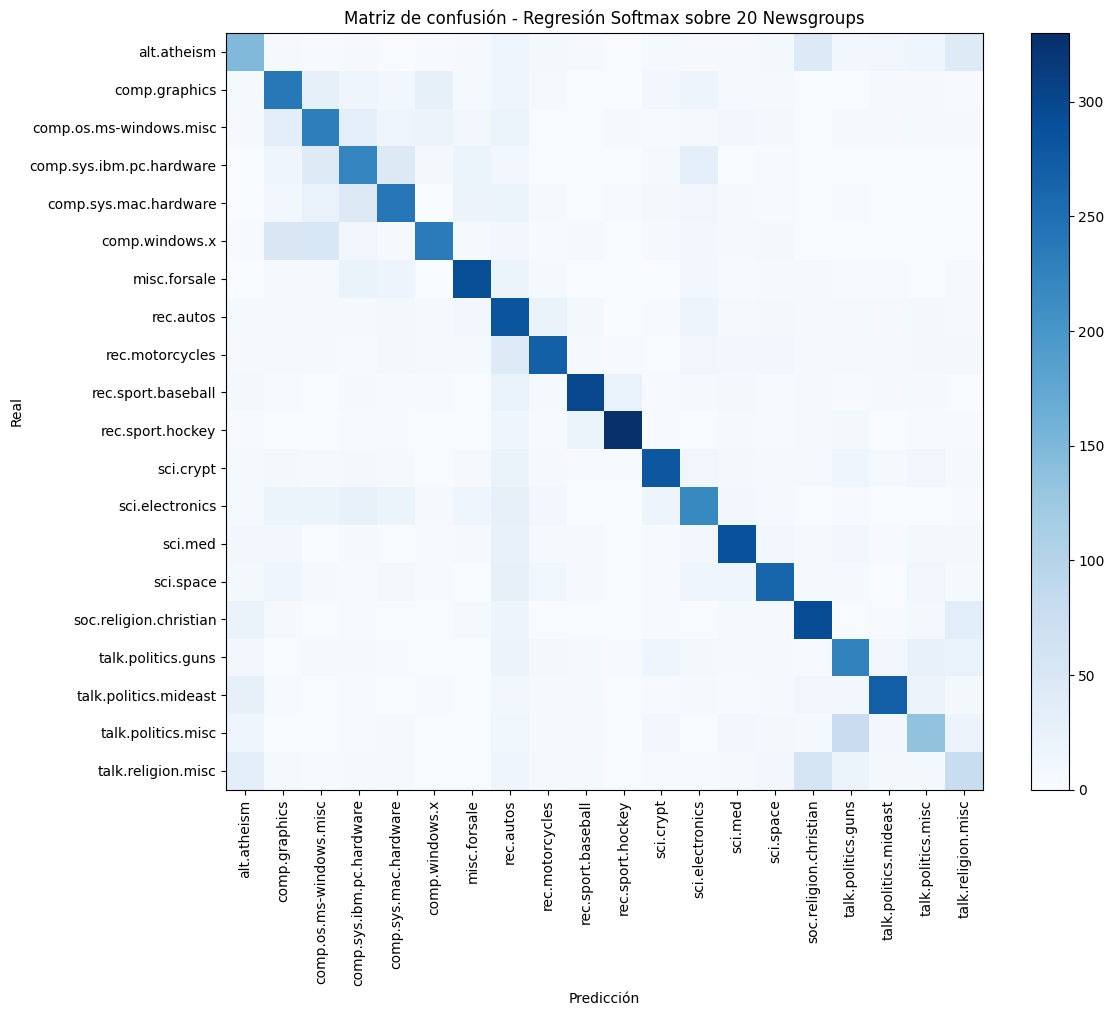

In [22]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


## 9. Preguntas de reflexión

**Sobre Regresión Softmax (teoría)**
1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?
2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?
3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?
4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?

**Sobre frameworks y herramientas**
5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?
6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?
7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?

**Sobre el experimento**
8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?
9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?
10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?

1. Con dos clases, la softmax es lo mismo que una sigmoide aplicada a la diferencia entre los dos logits. Por eso la regresión softmax es la versión multiclase de la regresión logística. Si NUM_CLASSES fuera 2, el modelo haría lo mismo que una regresión logística, solo que con el doble de pesos de los necesarios, porque lo único que importa es la diferencia entre los pesos de las dos clases.

2. CrossEntropyLoss ya incluye la softmax adentro, y la calcula de una forma numéricamente estable. Si además la aplicáramos en el forward, quedaría aplicada dos veces. Las probabilidades saldrían casi iguales para todas las clases, la loss no podría bajar mucho y el modelo aprendería mucho más lento.

3. El modelo solo puede separar las clases con fronteras rectas (hiperplanos). Si un problema necesita fronteras curvas, o depende de combinaciones de palabras (por ejemplo, que "not" le cambie el sentido a "good"), no lo puede resolver. En este caso no es una gran limitación: con tantas palabras en el vocabulario, las clases ya son casi separables con fronteras lineales.

4. Una red con capas ocultas agrega funciones no lineales, así que puede aprender combinaciones de features y fronteras más complejas. La regresión softmax es más simple, más rápida y más fácil de interpretar. Conviene cuando hay pocos datos, cuando los vectores de entrada son grandes y dispersos (como con TF-IDF), o como punto de partida. La red conviene cuando hay muchos datos y las relaciones entre features son más complejas.

5. PyTorch da más control sobre el entrenamiento, permite usar GPU y hace fácil pasar a un modelo más complejo. La desventaja es que hay que escribir más código y ajustar más cosas a mano: learning rate, épocas, regularización. Con sklearn se resuelve en pocas líneas, trae regularización por defecto y trabaja directo con matrices dispersas, pero es menos flexible.

6. MLflow sirvió para guardar los hiperparámetros, las métricas y el modelo de cada corrida, y así poder compararlas y reproducirlas. TensorBoard sirve más que nada para ver las curvas de loss y accuracy durante el entrenamiento. Uno muestra cómo entrena el modelo, y el otro registra qué se probó y qué resultado dio.

7. Optuna encontró una buena configuración probando pocas combinaciones. En vez de probar al azar, usa los resultados anteriores para decidir qué probar después, y fue concentrándose en las opciones que mejor funcionaban. Hacer lo mismo a mano hubiera llevado mucho más tiempo, y además cuesta ver cómo interactúan los parámetros entre sí.

8. La mejor combinación fue sacar stopwords, usar stemming y quedarse solo con palabras sueltas (sin bigramas), con el vocabulario más grande que se probó. Tiene sentido: el tema de un post se reconoce por sus palabras de contenido, las stopwords no aportan, y el stemming junta variantes de la misma palabra. Los bigramas no ayudaron, porque ocupan lugar en el vocabulario sin sumar mucha información.

9. El modelo se confunde más entre categorías que tratan temas parecidos:

Las de religión y ateísmo entre sí.
Las de política entre sí, sobre todo politics.misc con politics.guns.
Las de computación entre sí.

Estas categorías usan casi las mismas palabras. En cambio, categorías como hockey se reconocen muy bien porque tienen palabras muy específicas.

10. Probablemente cambiaría poco. Estas confusiones no vienen de que el modelo sea lineal, sino de que las categorías comparten vocabulario y de que TF-IDF pierde el orden y el contexto de las palabras. Una red más compleja podría mejorar un poco, pero también sobreajustaría más.